### 1. Persiapan pustaka

Bagian ini mengimpor pustaka yang diperlukan untuk membaca dan mengolah data (`pandas`, `numpy`), membuat grafik (`matplotlib` dan `seaborn`), membagi data, melakukan standardisasi, serta membangun model Decision Tree untuk regresi. Pengaturan `warnings` menyembunyikan pesan peringatan, sedangkan `sns.set_theme` mengatur tampilan grafik.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

**Penjelasan:** Mengimpor pustaka yang digunakan: Pandas dan NumPy untuk pengolahan data, Matplotlib dan Seaborn untuk grafik, serta fungsi Scikit-learn untuk pembagian data, standardisasi, model, dan validasi silang.

### 2. Memuat dataset

Kode membaca dataset dari file `insurance.csv` ke dalam DataFrame bernama `df`. `shape` menampilkan jumlah baris dan kolom, sedangkan `head()` memperlihatkan lima baris pertama untuk memastikan data berhasil dimuat dan kolomnya sesuai.

In [2]:
df = pd.read_csv('insurance.csv')

print("Data berhasil dimuat!")
print("Jumlah baris dan kolom:", df.shape)

df.head()

Data berhasil dimuat!
Jumlah baris dan kolom: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


**Penjelasan:** `pd.read_csv()` membaca `insurance.csv` ke dalam `df`. `df.shape` menunjukkan jumlah baris dan kolom, sedangkan `df.head()` menampilkan lima data pertama.

### 3. Memeriksa kondisi awal data

Sel ini menampilkan tipe data dan jumlah nilai pada setiap kolom, statistik deskriptif untuk kolom numerik, serta ringkasan kolom kategorikal. Pemeriksaan nilai kosong dan duplikat membantu mengetahui masalah kualitas data sebelum proses pembersihan.

In [3]:
# Informasi dataset
df.info()

# Statistik deskriptif
display(df.describe())

# Statistik kolom kategorikal
display(df.describe(include='object'))

# Memeriksa missing values
print("Missing values setiap kolom:")
print(df.isnull().sum())

# Memeriksa jumlah data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


Missing values setiap kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Jumlah data duplikat: 1


**Penjelasan:** `df.info()` memeriksa struktur dan tipe data; `describe()` merangkum statistik numerik/kategorikal; `isnull().sum()` menghitung nilai kosong; `duplicated().sum()` menghitung baris duplikat.

### 4. Membersihkan data

Kode menghapus baris duplikat, lalu memeriksa kembali nilai kosong. Jika ditemukan nilai kosong, kolom kategorikal diisi dengan modus dan kolom numerik diisi dengan median. Pemeriksaan terakhir memastikan kondisi data setelah pembersihan.

In [4]:
# Menghapus data duplikat
df = df.drop_duplicates().copy()

print("Jumlah data setelah menghapus duplikat:", df.shape)

# Memeriksa kembali missing values
print("\nMissing values setelah menghapus duplikat:")
print(df.isnull().sum())

# Mengisi missing values jika ada
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == 'object':
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

print("\nJumlah missing values setelah cleaning:")
print(df.isnull().sum())

display(df.head())

Jumlah data setelah menghapus duplikat: (1337, 7)

Missing values setelah menghapus duplikat:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah missing values setelah cleaning:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


**Penjelasan:** `drop_duplicates()` menghapus baris duplikat. Perulangan memeriksa setiap kolom dan mengisi nilai kosong dengan modus untuk kategori atau median untuk angka.

### 5. Mengidentifikasi pencilan dengan IQR

Untuk kolom `age`, `bmi`, `children`, dan `charges`, kode menghitung kuartil pertama (Q1), kuartil ketiga (Q3), dan rentang antarkuartil (IQR). Nilai di luar batas Q1 − 1,5×IQR dan Q3 + 1,5×IQR dihitung sebagai pencilan. Kode ini hanya menghitung jumlah pencilan, bukan menghapusnya.

In [5]:
kolom_numerik = ['age', 'bmi', 'children', 'charges']

for col in kolom_numerik:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ).sum()

    print(f"{col}: {jumlah_outlier} outlier")

age: 0 outlier
bmi: 9 outlier
children: 0 outlier
charges: 139 outlier


**Penjelasan:** `quantile()` menghitung kuartil Q1 dan Q3. IQR adalah selisih Q3–Q1; batas Q1−1,5×IQR dan Q3+1,5×IQR digunakan untuk menghitung kandidat pencilan, bukan langsung menghapusnya.

### 6. Visualisasi pencilan

Boxplot dibuat untuk setiap kolom numerik agar sebaran data dan nilai yang berada jauh dari rentang utama lebih mudah diamati. Pencilan pada biaya asuransi tidak otomatis berarti kesalahan karena bisa mencerminkan biaya yang memang tinggi.

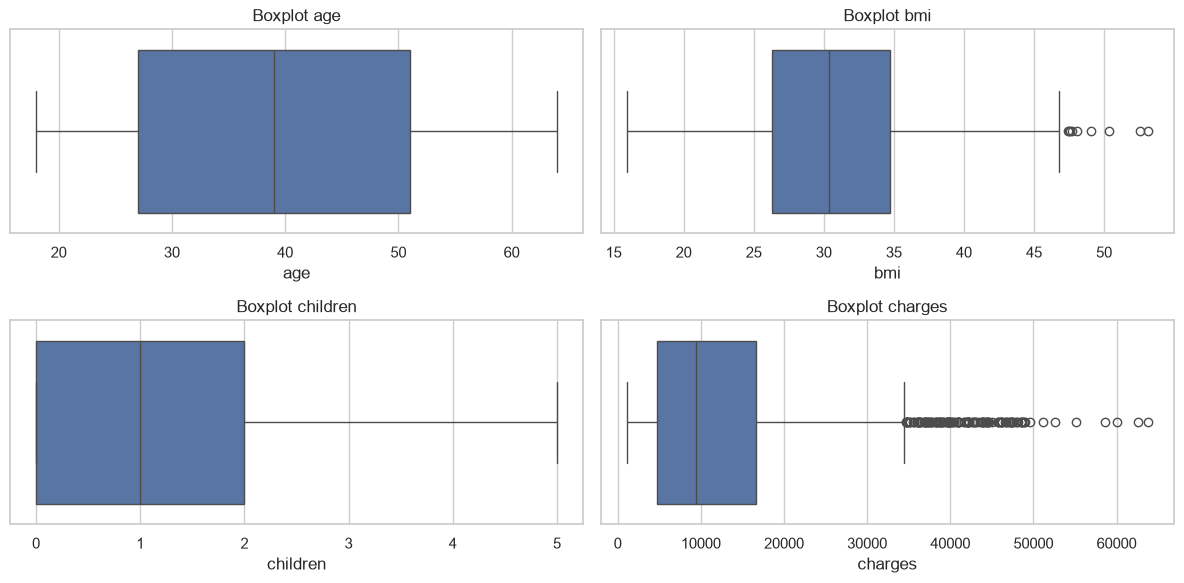

In [6]:
plt.figure(figsize=(12, 6))

for i, col in enumerate(kolom_numerik, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x=df[col], color='C0')
    plt.title(f'Boxplot {col}')

plt.tight_layout()
plt.show()

**Penjelasan:** `figure()` menentukan ukuran kanvas, `subplot()` membagi area menjadi empat grafik, dan `boxplot()` menampilkan median, sebaran, serta kandidat pencilan untuk setiap kolom numerik.

### 7. Mengubah fitur kategorikal menjadi angka

Fungsi `pd.get_dummies()` mengubah kolom `sex`, `smoker`, dan `region` menjadi kolom indikator numerik agar dapat digunakan oleh algoritma machine learning. `drop_first=True` menghilangkan satu kategori acuan pada setiap fitur untuk mengurangi redundansi.

In [7]:
df_encoded = pd.get_dummies(
    df,
    columns=['sex', 'smoker', 'region'],
    drop_first=True,
    dtype=int
)

print("Dataset setelah encoding:")
display(df_encoded.head())

print("Ukuran dataset setelah encoding:", df_encoded.shape)

Dataset setelah encoding:


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


Ukuran dataset setelah encoding: (1337, 9)


**Penjelasan:** `pd.get_dummies()` mengubah kategori `sex`, `smoker`, dan `region` menjadi kolom indikator 0/1. `drop_first=True` menghilangkan satu kategori acuan.

### 8. Distribusi biaya asuransi

Histogram menunjukkan frekuensi nilai `charges`, sedangkan garis KDE memberikan gambaran bentuk distribusinya. Grafik ini membantu melihat apakah biaya terkonsentrasi pada rentang tertentu atau memiliki ekor panjang.

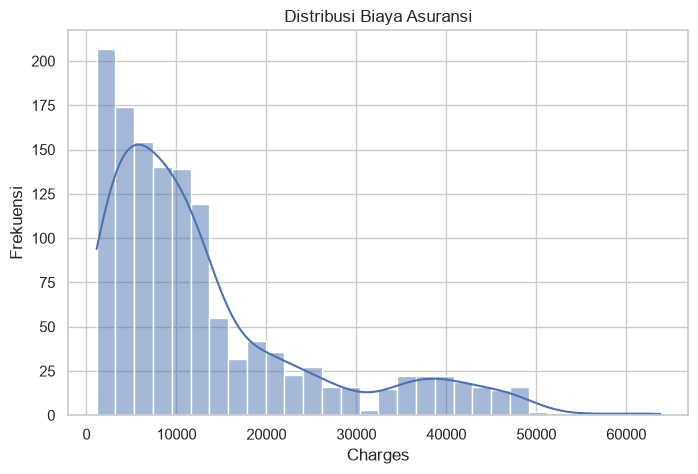

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='charges',
    bins=30,
    kde=True,
    color='C0'
)

plt.title('Distribusi Biaya Asuransi')
plt.xlabel('Charges')
plt.ylabel('Frekuensi')
plt.show()

**Penjelasan:** `histplot()` menampilkan distribusi biaya asuransi. `bins` menentukan jumlah batang, sedangkan `kde=True` menambahkan kurva kepadatan.

### 9. Distribusi usia

Histogram usia memperlihatkan sebaran peserta dalam dataset. Informasi ini membantu memahami rentang usia yang paling banyak muncul sebelum model dibangun.

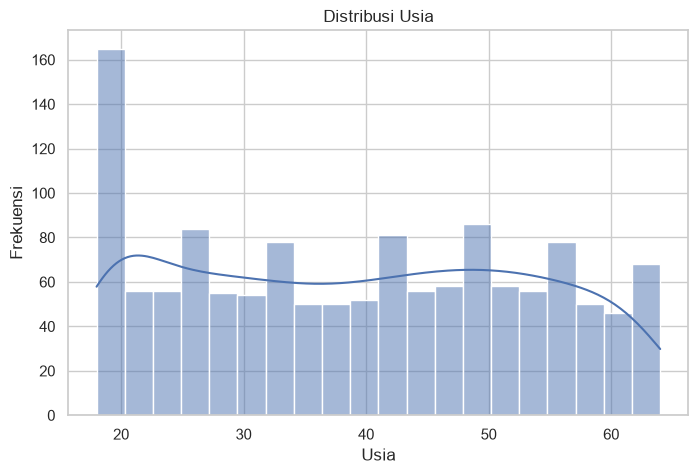

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='age',
    bins=20,
    kde=True,
    color='C0'
)

plt.title('Distribusi Usia')
plt.xlabel('Usia')
plt.ylabel('Frekuensi')
plt.show()

**Penjelasan:** `histplot()` menunjukkan sebaran usia peserta; sumbu X berisi usia dan sumbu Y menunjukkan frekuensi.

### 10. Jumlah peserta berdasarkan status merokok

Countplot menghitung jumlah data untuk setiap kategori pada kolom `smoker`. Grafik ini menunjukkan keseimbangan jumlah peserta yang merokok dan tidak merokok di dalam dataset.

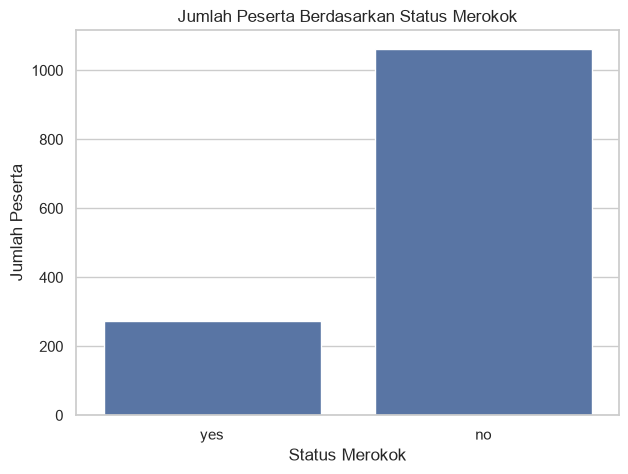

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='smoker',
    color='C0'
)

plt.title('Jumlah Peserta Berdasarkan Status Merokok')
plt.xlabel('Status Merokok')
plt.ylabel('Jumlah Peserta')
plt.show()

**Penjelasan:** `countplot()` menghitung jumlah data pada tiap kategori status merokok sehingga komposisi peserta dapat dibandingkan.

### 11. Korelasi antarvariabel numerik

Kode menghitung korelasi Pearson antara `age`, `bmi`, `children`, dan `charges`, lalu menampilkannya dalam heatmap. Nilai mendekati 1 menunjukkan hubungan linear positif, mendekati -1 hubungan linear negatif, dan mendekati 0 hubungan linear yang lemah. Korelasi tidak otomatis berarti sebab-akibat.

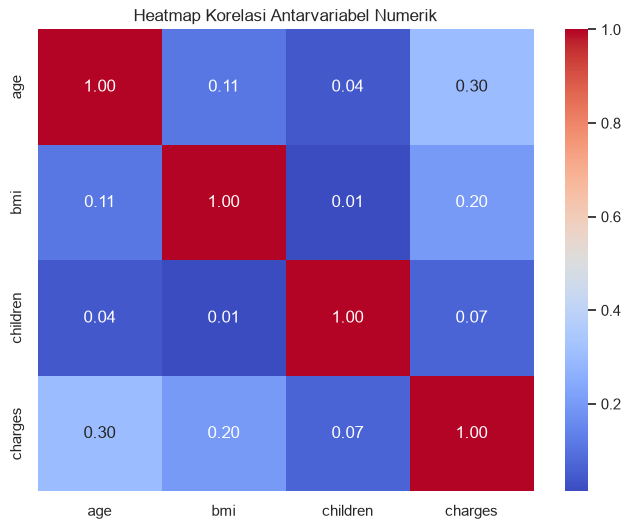

In [11]:
plt.figure(figsize=(8, 6))

korelasi = df[
    ['age', 'bmi', 'children', 'charges']
].corr()

sns.heatmap(
    korelasi,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Heatmap Korelasi Antarvariabel Numerik')
plt.show()

**Penjelasan:** `corr()` menghitung korelasi Pearson antarfitur numerik. `heatmap()` menampilkan nilai korelasi dalam bentuk warna dan angka; korelasi tidak selalu berarti sebab-akibat.

### 12. Biaya berdasarkan status merokok

Boxplot membandingkan distribusi `charges` antara peserta yang merokok dan tidak merokok. Median, rentang antarkuartil, dan pencilan dapat digunakan untuk melihat perbedaan distribusi biaya di antara kedua kelompok.

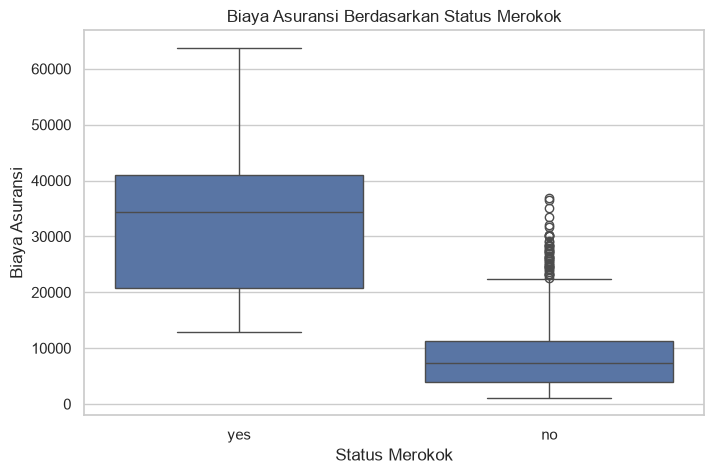

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='smoker',
    y='charges',
    color='C0'
)

plt.title('Biaya Asuransi Berdasarkan Status Merokok')
plt.xlabel('Status Merokok')
plt.ylabel('Biaya Asuransi')
plt.show()

**Penjelasan:** `boxplot()` membandingkan distribusi biaya asuransi antara perokok dan bukan perokok, termasuk median dan rentang data.

### 13. Biaya berdasarkan wilayah

Boxplot ini membandingkan distribusi biaya asuransi untuk setiap kategori `region`. Grafik membantu melihat apakah median dan variasi biaya berbeda antarwilayah.

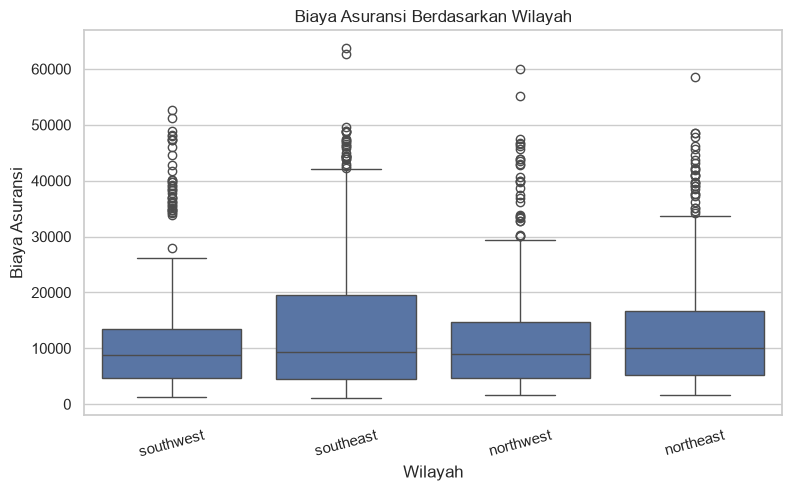

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='region',
    y='charges',
    color='C0'
)

plt.title('Biaya Asuransi Berdasarkan Wilayah')
plt.xlabel('Wilayah')
plt.ylabel('Biaya Asuransi')
plt.xticks(rotation=15)
plt.show()

**Penjelasan:** `boxplot()` membandingkan sebaran biaya asuransi antarwilayah. `xticks(rotation=15)` memiringkan label agar lebih mudah dibaca.

### 14. Rata-rata biaya berdasarkan status merokok

Kode menghitung rata-rata `charges` untuk tiap kategori `smoker`, menampilkan nilainya, lalu membuat grafik batang. Perbandingan ini melengkapi boxplot dengan ringkasan rata-rata biaya tiap kelompok.

Rata-rata biaya asuransi berdasarkan status merokok:


smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

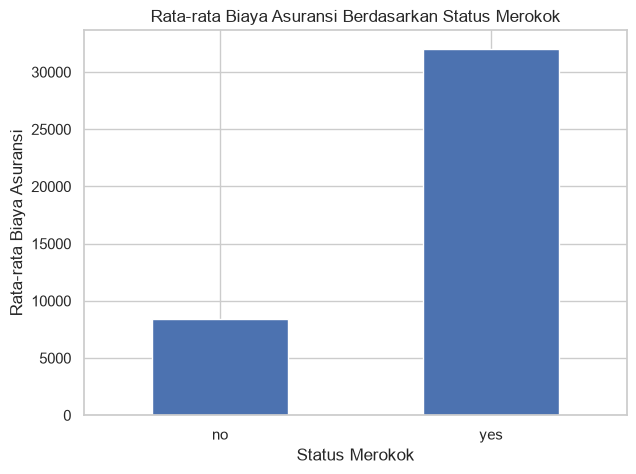

In [14]:
rata_charges_smoker = df.groupby('smoker')['charges'].mean()

print("Rata-rata biaya asuransi berdasarkan status merokok:")
display(rata_charges_smoker)

rata_charges_smoker.plot(
    kind='bar',
    figsize=(7, 5),
    color='C0'
)

plt.title('Rata-rata Biaya Asuransi Berdasarkan Status Merokok')
plt.xlabel('Status Merokok')
plt.ylabel('Rata-rata Biaya Asuransi')
plt.xticks(rotation=0)
plt.show()

**Penjelasan:** `groupby('smoker')['charges'].mean()` menghitung rata-rata biaya untuk tiap status merokok. `plot(kind='bar')` menyajikan perbandingan tersebut sebagai grafik batang.

### 15. Hubungan usia dan biaya asuransi

Scatterplot menampilkan hubungan antara `age` dan `charges`; warna menunjukkan status merokok. Pola titik dapat membantu mengamati apakah biaya cenderung berubah seiring usia dan apakah pola tersebut berbeda menurut status merokok.

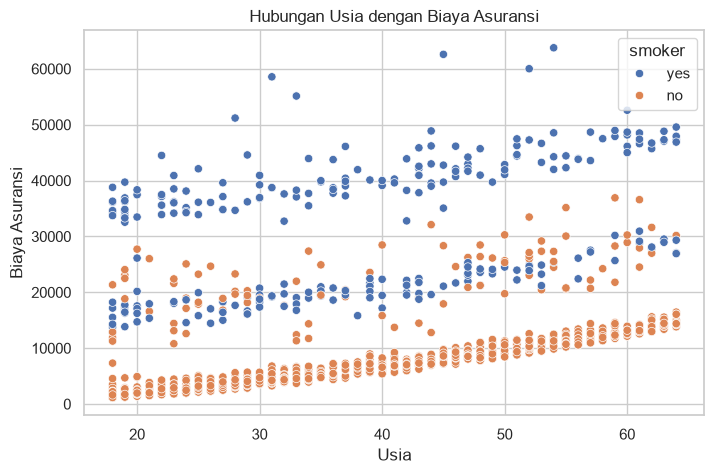

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='age',
    y='charges',
    hue='smoker'
)

plt.title('Hubungan Usia dengan Biaya Asuransi')
plt.xlabel('Usia')
plt.ylabel('Biaya Asuransi')
plt.show()

**Penjelasan:** `scatterplot()` menampilkan hubungan usia dan biaya asuransi. `hue='smoker'` membedakan titik berdasarkan status merokok.

### 16. Hubungan BMI dan biaya asuransi

Scatterplot ini membandingkan BMI dengan biaya asuransi dan menggunakan warna untuk membedakan status merokok. Grafik membantu mengamati pola hubungan dan sebaran biaya pada rentang BMI yang berbeda.

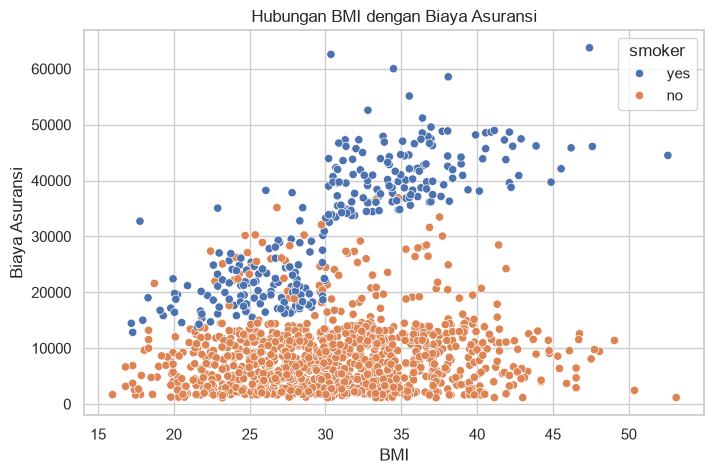

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='bmi',
    y='charges',
    hue='smoker'
)

plt.title('Hubungan BMI dengan Biaya Asuransi')
plt.xlabel('BMI')
plt.ylabel('Biaya Asuransi')
plt.show()

**Penjelasan:** `scatterplot()` menampilkan hubungan BMI dan biaya asuransi, dengan warna yang membedakan status merokok.

### 17. Rata-rata biaya berdasarkan wilayah

Kode menghitung rata-rata biaya asuransi pada setiap wilayah, mengurutkannya dari nilai tertinggi ke terendah, lalu menampilkan tabel dan grafik batang. Urutan ini memudahkan perbandingan rata-rata antarkategori wilayah.

Rata-rata biaya asuransi berdasarkan wilayah:


region
southeast    14735.411438
northeast    13406.384516
northwest    12450.840844
southwest    12346.937377
Name: charges, dtype: float64

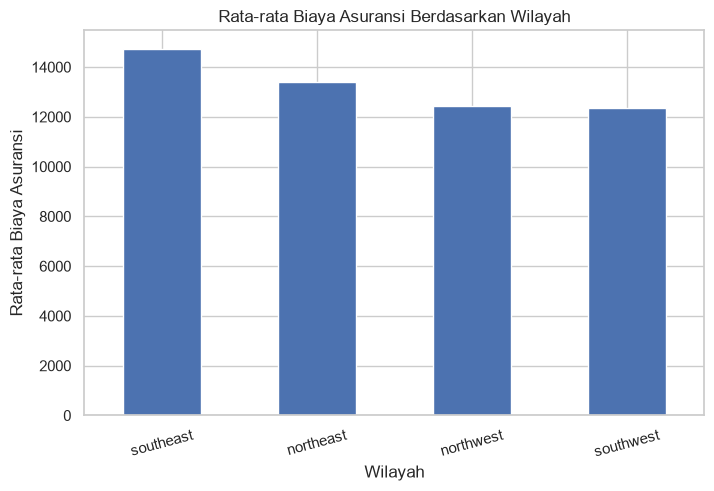

In [17]:
rata_charges_region = (
    df.groupby('region')['charges']
    .mean()
    .sort_values(ascending=False)
)

print("Rata-rata biaya asuransi berdasarkan wilayah:")
display(rata_charges_region)

rata_charges_region.plot(
    kind='bar',
    figsize=(8, 5),
    color='C0'
)

plt.title('Rata-rata Biaya Asuransi Berdasarkan Wilayah')
plt.xlabel('Wilayah')
plt.ylabel('Rata-rata Biaya Asuransi')
plt.xticks(rotation=15)
plt.show()

**Penjelasan:** `groupby()` mengelompokkan data berdasarkan wilayah, `mean()` menghitung rata-rata biaya, dan `sort_values()` mengurutkan hasil dari terbesar ke terkecil.

### 18. Korelasi fitur numerik terhadap biaya

Kode mengambil korelasi masing-masing fitur numerik dengan `charges`, lalu mengurutkan hasilnya dari korelasi tertinggi ke terendah. Hasil ini merupakan gambaran hubungan linear sederhana dan tidak menjelaskan seluruh hubungan yang mungkin ada.

In [18]:
korelasi_charges = (
    df[['age', 'bmi', 'children', 'charges']]
    .corr()['charges']
    .sort_values(ascending=False)
)

print("Korelasi setiap variabel numerik dengan charges:")
display(korelasi_charges)

Korelasi setiap variabel numerik dengan charges:


charges     1.000000
age         0.298308
bmi         0.198401
children    0.067389
Name: charges, dtype: float64

**Penjelasan:** `corr()['charges']` mengambil korelasi tiap fitur numerik terhadap biaya asuransi, lalu `sort_values()` mengurutkan hasilnya.

### 19. Memisahkan fitur, target, dan data latih/uji

Variabel `X` berisi semua kolom prediktor selain `charges`, sedangkan `y` adalah target biaya yang ingin diprediksi. `train_test_split` membagi data menjadi 80% data latih dan 20% data uji. `random_state=42` membuat pembagian dapat direproduksi.

In [19]:
# Memisahkan fitur dan target
X = df.drop(columns=['charges'])
y = df['charges']

# Membagi data: 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing :", X_test.shape[0])
print("Proporsi training   :", round(len(X_train) / len(df) * 100, 1), "%")
print("Proporsi testing    :", round(len(X_test) / len(df) * 100, 1), "%")

Jumlah data training: 1069
Jumlah data testing : 268
Proporsi training   : 80.0 %
Proporsi testing    : 20.0 %


**Penjelasan:** `X` berisi fitur prediktor dan `y` berisi target `charges`. `train_test_split()` membagi data menjadi 80% latih dan 20% uji; `random_state=42` membuat pembagian konsisten.

### 20. Preprocessing data latih dan uji

Kode melakukan One-Hot Encoding secara terpisah setelah data dibagi, kemudian menyamakan kolom data uji dengan data latih. `StandardScaler` dilatih hanya pada data latih (`fit_transform`) dan digunakan untuk mentransformasi data uji (`transform`) agar informasi data uji tidak bocor ke proses pelatihan. Fitur numerik yang distandardisasi adalah `age`, `bmi`, dan `children`.

In [20]:
# One-Hot Encoding dilakukan setelah pembagian data
kolom_kategorikal = ['sex', 'smoker', 'region']
kolom_numerik_model = ['age', 'bmi', 'children']

X_train_encoded = pd.get_dummies(
    X_train,
    columns=kolom_kategorikal,
    drop_first=True,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=kolom_kategorikal,
    drop_first=True,
    dtype=int
)

# Menyamakan kolom data testing dengan data training
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Standardisasi fitur numerik: fit hanya pada data training
scaler = StandardScaler()
X_train_encoded[kolom_numerik_model] = scaler.fit_transform(
    X_train_encoded[kolom_numerik_model]
)
X_test_encoded[kolom_numerik_model] = scaler.transform(
    X_test_encoded[kolom_numerik_model]
)

print("Ukuran fitur training setelah preprocessing:", X_train_encoded.shape)
print("Ukuran fitur testing setelah preprocessing :", X_test_encoded.shape)
display(X_train_encoded.head())

Ukuran fitur training setelah preprocessing: (1069, 8)
Ukuran fitur testing setelah preprocessing : (268, 8)


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
1114,-1.157680,-0.996928,-0.907908,1,0,0,0,0
968,-1.300619,-0.792762,0.766904,1,0,0,0,0
599,0.914926,1.154664,0.766904,0,0,1,0,0
170,1.701087,1.806837,-0.907908,1,0,0,1,0
275,0.557580,-0.651417,0.766904,0,0,0,0,0


**Penjelasan:** `pd.get_dummies()` mengubah kategori `sex`, `smoker`, dan `region` menjadi kolom indikator 0/1. `drop_first=True` menghilangkan satu kategori acuan.

### 21. Melatih model Decision Tree Regressor

Kode membuat model `DecisionTreeRegressor` dan melatihnya dengan fitur serta target pada data latih melalui `fit()`. Model regresi ini mempelajari pola untuk memperkirakan nilai biaya asuransi. Jumlah fitur yang digunakan ditampilkan sebagai pemeriksaan hasil preprocessing.

In [21]:
model = DecisionTreeRegressor(random_state=42)
model.fit(X_train_encoded, y_train)

print("Model DecisionTreeRegressor berhasil dilatih.")
print("Jumlah fitur yang digunakan:", X_train_encoded.shape[1])

Model DecisionTreeRegressor berhasil dilatih.
Jumlah fitur yang digunakan: 8


**Penjelasan:** `DecisionTreeRegressor()` membuat model regresi berbasis pohon keputusan. `fit()` melatih model menggunakan fitur data latih dan nilai `charges` yang diketahui.

### 22. Evaluasi dengan validasi silang

Validasi silang 5-fold membagi data latih menjadi lima bagian bergantian untuk menilai kestabilan model menggunakan metrik R². Kode menampilkan nilai R² setiap fold, rata-ratanya, dan standar deviasi. Nilai R² yang lebih tinggi umumnya menunjukkan kecocokan prediksi yang lebih baik, sedangkan standar deviasi memberi gambaran variasi antar-fold.

In [22]:
cv_scores = cross_val_score(
    model,
    X_train_encoded,
    y_train,
    cv=5,
    scoring='r2'
)

print("Nilai R² setiap fold:", np.round(cv_scores, 4))
print("Rata-rata R²:", round(cv_scores.mean(), 4))
print("Standar deviasi R²:", round(cv_scores.std(), 4))

Nilai R² setiap fold: [0.7279 0.6793 0.6674 0.5925 0.6797]
Rata-rata R²: 0.6694
Standar deviasi R²: 0.0437


**Penjelasan:** `cross_val_score()` menjalankan validasi silang 5-fold dengan metrik R². Rata-rata menunjukkan performa umum antarfold, sedangkan standar deviasi menunjukkan variasi skornya.